# Ⅰ第7回 演習1 16 セルを測る ― 枚数と幅を 2 倍にすると，誤り率はどれだけ下がるか

**問い**：訓練枚数を 2 倍にするのと，モデルの幅を 2 倍にするのでは，どちらが誤り率を下げるか．

| 用語 | 意味 |
|---|---|
| スケーリング則 | データの量やモデルの大きさを 2 倍にするたびに，誤り率がほぼ同じ割合で下がるという経験則．両方の軸を対数にしたグラフ（log-log）で直線になる |
| セル | 訓練枚数とモデルの幅の組み合わせ 1 つ．今日は 4 × 4 ＝ 16 セル |
| 誤り率 | 100 − テスト正解率（%）．小さいほど良い |
| 外挿 | 測った範囲の外（今日は 4000 枚より多い 16000 枚）を，測った点から予想すること |

- データは FashionMNIST（第1回 GW3 と同じ 28×28・10 クラス）．テストは 10,000 枚
- モデルは 2 層の CNN（`common/scaling.py`）．幅は 1 層目のチャネル数（2 層目はその 2 倍）
- 16 セル × シード 0〜2 ＝ 48 回（教員機で約 25 秒．ノート PC ではその数倍）
- 結果は `results/c1_d7_ex1.csv` に記録され，演習2 で読む．`MEMBER_NO` は演習2 でも同じ番号にする
- LLM は使わない

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 2                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/niirowakana/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 一番良い（誤り率が小さい）セル：枚数 4000・幅 32　誤り率 13%
- 一番悪いセル：枚数 500・幅 4　誤り率 35%
- 枚数を 2 倍にするのと幅を 2 倍にするのでは，どちらが効くか：枚数を2倍にする方（このモデルは小さいので、幅を広げるより見せる画像を増やすほうが効くと思う）

## (確認) スケーリング則

授業ページの「演習1」を読んでから答える．**全問正解すると先へ進める**（ちがうとヒントが出る）．

**Q1**　両方の軸を対数にしたグラフで，横軸の 500 → 1000 と 2000 → 4000 の長さ（目盛りの間隔）はどうなるか
- ア 2000 → 4000 のほうが 4 倍長い
- イ 同じ長さ（どちらも 2 倍）
- ウ 500 → 1000 のほうが長い

**Q2**　log-log のグラフで直線の傾きが −0.3 のとき，枚数を 2 倍にすると誤り率は何倍になるか
- ア 約 0.81 倍（2 の −0.3 乗）
- イ 0.7 倍（1 − 0.3）
- ウ 0.3 倍

**Q3**　幅を 2 倍にすると，パラメータの数はどうなるか（このモデルは畳み込み 2 層と全結合 1 層）
- ア 変わらない
- イ ちょうど 2 倍
- ウ 2 倍より多く，4 倍以下

In [2]:
from common.todo import checkpoint, quiz_check, todo_check
# ▼ 下の " " の中に，ア・イ・ウのどれかを書いて実行する
Q1 = "イ"
Q2 = "ア"
Q3 = "ウ"
quiz_check({    # 2 つ目の値は答え合わせ用の暗号（答えは書いていない）
    "Q1": (Q1, "86c731cb", "対数の軸では，同じ倍率は同じ長さになる"),
    "Q2": (Q2, "eb95be22", "log10(誤り率) が 0.3 × log10(2) だけ下がる → 2 の −0.3 乗 ≒ 0.81 倍"),
    "Q3": (Q3, "7720d533", "2 層目の畳み込みは入力・出力のチャネルが両方 2 倍で 4 倍．全結合は 2 倍．合わせて 2〜4 倍"),
})

Q1：正解．対数の軸では，同じ倍率は同じ長さになる
Q2：正解．log10(誤り率) が 0.3 × log10(2) だけ下がる → 2 の −0.3 乗 ≒ 0.81 倍
Q3：正解．2 層目の畳み込みは入力・出力のチャネルが両方 2 倍で 4 倍．全結合は 2 倍．合わせて 2〜4 倍
全問正解．実験に進んでよい


## (1) 16 セルをシード 0〜2 で回す

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common.device import get_device
from common.logger import ResultLogger
from common.scaling import run, N_TRAIN, WIDTHS, SEEDS
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

device = get_device()
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d7", exercise="ex1", device=device)
rows = []
for width in WIDTHS:
    for n in N_TRAIN:
        for seed in SEEDS:
            r = run(n, width, seed=seed, device=device)
            logger.log_many({k: r[k] for k in ["test_error", "params", "train_sec"]}, condition=f"n{n}_w{width}", seed=seed)
            rows.append(r)
        print(f"幅 {width:2d}・{n:4d} 枚：誤り率 {np.mean([x['test_error'] for x in rows[-3:]]):.1f}%（3 回の平均・1 回 {r['train_sec']:.1f} 秒）")
df = pd.DataFrame(rows)
print("記録した CSV:", logger.path)

幅  4・ 500 枚：誤り率 37.1%（3 回の平均・1 回 0.1 秒）
幅  4・1000 枚：誤り率 29.2%（3 回の平均・1 回 0.2 秒）
幅  4・2000 枚：誤り率 25.4%（3 回の平均・1 回 0.5 秒）
幅  4・4000 枚：誤り率 19.8%（3 回の平均・1 回 1.0 秒）
幅  8・ 500 枚：誤り率 30.7%（3 回の平均・1 回 0.1 秒）
幅  8・1000 枚：誤り率 24.8%（3 回の平均・1 回 0.4 秒）
幅  8・2000 枚：誤り率 21.3%（3 回の平均・1 回 0.7 秒）
幅  8・4000 枚：誤り率 17.6%（3 回の平均・1 回 1.6 秒）
幅 16・ 500 枚：誤り率 28.2%（3 回の平均・1 回 0.3 秒）
幅 16・1000 枚：誤り率 22.6%（3 回の平均・1 回 0.5 秒）
幅 16・2000 枚：誤り率 18.6%（3 回の平均・1 回 1.2 秒）
幅 16・4000 枚：誤り率 15.7%（3 回の平均・1 回 1.8 秒）
幅 32・ 500 枚：誤り率 25.5%（3 回の平均・1 回 0.4 秒）
幅 32・1000 枚：誤り率 20.1%（3 回の平均・1 回 0.9 秒）
幅 32・2000 枚：誤り率 16.6%（3 回の平均・1 回 1.7 秒）
幅 32・4000 枚：誤り率 15.0%（3 回の平均・1 回 3.4 秒）
記録した CSV: /Users/niirowakana/AI_TD/results/c1_d7_ex1.csv


## (2) 16 セルの表（3 回の平均と標準偏差）

In [4]:
mean = df.pivot_table(index="width", columns="n_train", values="test_error", aggfunc="mean")
sd = df.pivot_table(index="width", columns="n_train", values="test_error", aggfunc="std")
params = df.groupby("width")["params"].first()
print("誤り率の平均（%）．行＝幅，列＝訓練枚数")
print(mean.round(1).to_string())
print("\n標準偏差")
print(sd.round(1).to_string())
print("\nパラメータの数：", ", ".join(f"幅 {w} → {p:,}" for w, p in params.items()))

誤り率の平均（%）．行＝幅，列＝訓練枚数
n_train  500   1000  2000  4000
width                          
4        37.1  29.2  25.4  19.8
8        30.7  24.8  21.3  17.6
16       28.2  22.6  18.6  15.7
32       25.5  20.1  16.6  15.0

標準偏差
n_train  500   1000  2000  4000
width                          
4         4.1   2.1   1.9   1.0
8         1.4   0.7   0.3   0.3
16        1.2   0.3   0.2   0.2
32        1.9   0.7   0.5   0.9

パラメータの数： 幅 4 → 4,266, 幅 8 → 9,098, 幅 16 → 20,490, 幅 32 → 50,186


## (3) TODO 1：枚数を 2 倍にすると，誤り率は何倍になるか

log-log のグラフの直線の傾き `slope` を，幅ごとに求める．`np.polyfit(x, y, 1)` は点 (x, y) に一番合う直線の **傾き** と **切片** を返す．

- `ns`：4 パターンの訓練枚数　`errs`：それぞれの誤り率の平均
- 横・縦とも `np.log10` をとってから渡す（log-log のグラフの上で直線を引く）
- 傾きの読み方：枚数を 2 倍にすると誤り率は `2 ** slope` 倍になる（傾き −0.3 なら約 0.81 倍．マイナスが大きいほどよく下がる）
- 左のグラフ＝幅ごとに枚数を増やしたとき．右のグラフ＝枚数ごとに幅（パラメータの数）を増やしたとき

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
slope, intercept = np.polyfit(np.log10(ns), np.log10(errs), 1)
```

</details>

幅  4：傾き -0.291 → 枚数を 2 倍にすると誤り率は 0.82 倍
幅  8：傾き -0.262 → 枚数を 2 倍にすると誤り率は 0.83 倍
幅 16：傾き -0.282 → 枚数を 2 倍にすると誤り率は 0.82 倍
幅 32：傾き -0.259 → 枚数を 2 倍にすると誤り率は 0.84 倍


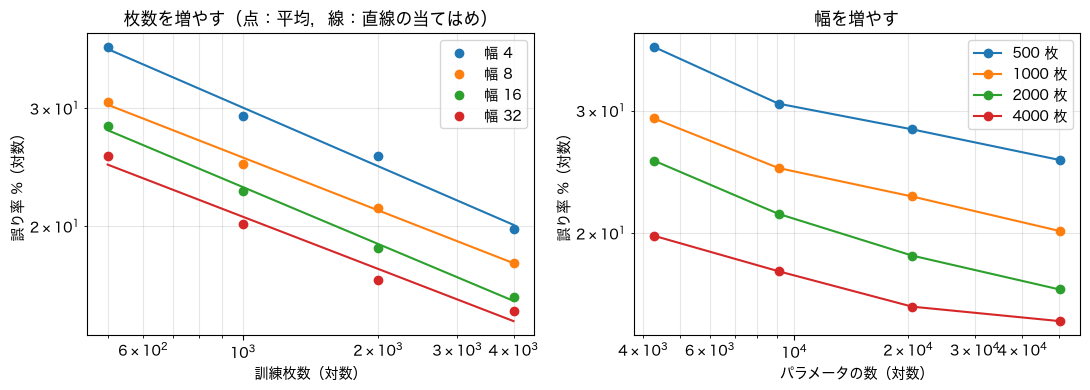

In [5]:
todo_check("TODO 1")   # 下の「...」が残っていたら，ここで止まる
ns = np.array(N_TRAIN)
fits = {}
for width in WIDTHS:
    errs = mean.loc[width].to_numpy()
    slope, intercept = np.polyfit(np.log10(ns), np.log10(errs), 1)   # np.polyfit(横の値, 縦の値, 1)．横・縦とも np.log10 をとってから渡す
    fits[width] = (slope, intercept)
    print(f"幅 {width:2d}：傾き {slope:.3f} → 枚数を 2 倍にすると誤り率は {2 ** slope:.2f} 倍")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for width in WIDTHS:
    slope, intercept = fits[width]
    line = ax[0].plot(ns, mean.loc[width], "o", label=f"幅 {width}")[0]
    ax[0].plot(ns, 10 ** (intercept + slope * np.log10(ns)), "-", color=line.get_color())
for n in N_TRAIN:
    ax[1].plot(params, mean[n], "o-", label=f"{n} 枚")
for a, xl in zip(ax, ["訓練枚数", "パラメータの数"]):
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel(xl + "（対数）"); a.set_ylabel("誤り率 %（対数）")
    a.grid(True, which="both", alpha=0.3); a.legend()
ax[0].set_title("枚数を増やす（点：平均，線：直線の当てはめ）"); ax[1].set_title("幅を増やす")
plt.tight_layout(); plt.show()

## (4) 2 倍にしたときの効き目を比べる

(2) の表で，隣の列（枚数が 2 倍）・隣の行（幅が 2 倍）との誤り率の比を平均する．**1 より小さいほど，よく効いている**．

In [6]:
by_n = (mean.iloc[:, 1:].to_numpy() / mean.iloc[:, :-1].to_numpy()).mean()   # 枚数を 2 倍にしたとき（隣の列との比）
by_w = (mean.iloc[1:].to_numpy() / mean.iloc[:-1].to_numpy()).mean()         # 幅を 2 倍にしたとき（隣の行との比）
print(f"枚数を 2 倍：誤り率は平均 {by_n:.2f} 倍")
print(f"幅を 2 倍  ：誤り率は平均 {by_w:.2f} 倍")
for n in (N_TRAIN[0], N_TRAIN[-1]):
    print(f"{n:4d} 枚で幅 {WIDTHS[0]} → {WIDTHS[-1]}：{mean.loc[WIDTHS[0], n]:.1f}% → {mean.loc[WIDTHS[-1], n]:.1f}%")

枚数を 2 倍：誤り率は平均 0.83 倍
幅を 2 倍  ：誤り率は平均 0.89 倍
 500 枚で幅 4 → 32：37.1% → 25.5%
4000 枚で幅 4 → 32：19.8% → 15.0%


## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：枚数を 2 倍にするのと幅を 2 倍にするのでは，どちらが効いたか．メンバーで傾きはそろったか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：自分の (3) の傾きと (4) の 2 つの倍率を見せる．根拠になる所：(4) の「500 枚と 4000 枚で幅を広げたときの下がり方」
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [7]:
# 問い：枚数を 2 倍にするのと幅を 2 倍にするのでは，どちらが効いたか．メンバーで傾きはそろったか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "枚数を2倍にするほうが効いた。枚数を2倍にすると誤り率は平均0.83倍、幅を2倍にすると0.89倍だった。傾きは幅によって-0.26〜-0.29で、ほぼそろっていた。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：枚数を2倍にするほうが効いた。枚数を2倍にすると誤り率は平均0.83倍、幅を2倍にすると0.89倍だった。傾きは幅によって-0.26〜-0.29で、ほぼそろっていた。


## 振り返り（このセルをダブルクリックして書く）

- 予測と比べて，当たったこと・外れたこと：一番良いセル（4000 枚・幅 32）と一番悪いセル（500 枚・幅 4）は予測どおりだった。誤り率は、一番良いセルが予測 13% に対して 15.0%、一番悪いセルが予測 35% に対して 37.1% で、どちらも予測より約 2 ポイント悪かった。枚数を 2 倍にするほうが効くという予測も当たり、枚数 2 倍は 0.83 倍、幅 2 倍は 0.89 倍だった。
- 枚数が少ないとき（500 枚）と多いとき（4000 枚）で，幅を広げる効き目は違ったか：違った。幅を 4 から 32 に広げると、500 枚では 37.1% → 25.5% と 11.6 ポイント下がったが、4000 枚では 19.8% → 15.0% と 4.8 ポイントしか下がらなかった。枚数が多いと、小さいモデルでもすでに誤り率が低いので、幅を広げる効き目が小さくなったと考える。